# Filtracja Non-Local Means

## Definicja

Kolejny "poziom wtajemniczenia" w zagadnienie filtracji obrazów to metoda Non-Local Means (NLM).
Została ona zaproponowana w pracy *A non-local algorithm for image denoising* autorstwa Antoni Buades, Bartomeu Coll, i Jean Michel Morel na konferencji CVPR w 2005 roku.

Filtr NLM dany jest zależnością:

\begin{equation}
\hat{I}(\mathbf{x}) = \sum_{\mathbf{p} \in V(\mathbf{x})} w(\mathbf{p},\mathbf{x})I(\mathbf{p})
\end{equation}

gdzie:
- $I$ - obraz wejściowy,
- $\hat{I}$ - obraz wyjściowy (przefiltrowany),
- $\mathbf{x}$ - współrzędne piksela obrazu,
- $V(\mathbf{x})$ - obszar poszukiwań piksela, dla którego przeprowadzana jest filtracja,
- $w$ - waga punktu $\mathbf{p}$ z obszaru poszukiwań.

Wróćmy na chwilę do filtracji bilateralnej. Tam waga danego piksela z kontekstu zależała od dwóch czynników - odległości przestrzennej pomiędzy pikselami oraz różnicy w jasności/kolorze pomiędzy pikselami (tzw. przeciwdziedzina).
Filtr NLM stanowi uogólnienie tej metody - do obliczania wag nie wykorzystuje się już pojedynczych pikseli ($\mathbf{p}$ i $\mathbf{x}$), a lokalne konteksty ($N(\mathbf{p})$ i $N(\mathbf{x})$).

Waga $w$ dana jest następującą zależnością:

\begin{equation}
w(\mathbf{p},\mathbf{x}) = \frac{1}{Z(\mathbf{x})}\exp(-\frac{|| v(N(\mathbf{p})) - v(N(\mathbf{x})) ||^2_{2}}{\alpha \sigma^2})
\end{equation}

gdzie:
- \begin{equation}
Z(\mathbf{x}) = \sum_{\mathbf{p} \in  V(\mathbf{x})} \exp(-\frac{|| v(N(\mathbf{p})) - v(N(\mathbf{x})) ||^2_{2}}{\alpha \sigma^2})
\end{equation},
- $|| \cdot ||$ - jest normą $L_2$ odległości pomiędzy dwoma kontekstami,
- $v$ oznacza mnożenie punktowe kontekstu $N$ przez dwuwymiarową maskę Gaussa o odpowiadających kontekstowi wymiarach,
- $\alpha$ > 0 - parametr sterujący filtracją,
- $\sigma$ - parametr szumu stacjonarnego występującego na obrazie (w przypadku szumu niestacjonarnego, parametr $\sigma$ musi zostać dopasowany lokalnie tj. $\sigma = \sigma(\mathbf{x})$).

## Analiza działania

Zastanówmy sie teraz jak działa filtra NLM. Najprościej to zrozumieć na rysunku.

![Ilustracja NLM](https://raw.githubusercontent.com/vision-agh/poc_sw/master/07_Bilateral/nlm.png)

1. Dla rozważanego piksela $\mathbf{x}$ definiujemy obszar poszukiwań $V(\mathbf{x})$. Uwaga - obszar poszukiwań ($V$) jest jednostką większą niż otocznie/kontekst ($N$).

2. Następnie, dla każdego z pikseli $\mathbf{p} \in  V(\mathbf{x})$ oraz samego $\mathbf{x}$ definiujemy otocznie/kontekst odpowiednio $N(\mathbf{p})$ i $N(\mathbf{x})$.

3. Wracamy do równania definiującego wagę  $w(\mathbf{p},\mathbf{x})$, a konkretnie do wyrażenia $|| v(N(\mathbf{p})) - v(N(\mathbf{x})) ||$. Przeanalizujmy co ono oznacza. Mamy dwa otoczenia: $N(\mathbf{p})$ i $N(\mathbf{x})$. Każde z nich mnożymy przez odpowiadającą maskę Gaussa - funkcja $v$. Otrzymujemy dwie macierze, które odejmujemy od siebie punktowo. Następnie obliczamy kwadrat z normy ($L_2$ definiujemy jako $||X||_2 = \sqrt{\sum_k|X_k|^2}$. Otrzymujemy zatem jedną liczbę, która opisuje nam podobieństwo otoczeń pikseli $\mathbf{x}$ i $\mathbf{p}$. Mała wartość oznacza otoczenia zbliżone, duża - różniące się. Ponieważ, z dokładnością do stałych, liczba ta stanowi wykładnik funkcji $e^{-x}$, to ostatecznie waga jest zbliżona do 1 dla otoczeń podobnych, a szybko maleje wraz z malejącym podobieństwem kontekstów.

4. Podsumowując. Jak wynika z powyższej analizy filtr NLM to taki filtr bilateralny, w którym zamiast pojedynczych pikseli porównuje się ich lokalne otoczenia. Wpływa to pozytywnie na jakość filtracji, niestety kosztem złożoności obliczeniowej.

## Implementacja

W ramach zadania należy zaimplementować filtr NLM, ocenić jego działanie w porównaniu do filtra Gaussa i bilateralnego oraz dokonać pomiaru czasu obliczeń (dla trzech wymienionych metod).

Jak już się zrozumie jak działa NLM, jego implementacja jest dość prosta.
Wartość parametru $\alpha$ należy dobrać eksperymentalnie.
Nie należy także "przesadzić" z rozmiarem obszaru poszukiwań (np. 11x11) oraz kontekstu (5x5 lub 3x3).

Wskazówki do implementacji:
- algorytm sprowadza się do dwóch podwójnych pętli for: zewnętrzne po pikselach, wewnętrzne po kolejnych obszarach przeszukań,
- przed realizacją trzeba przemyśleć problem pikseli brzegowych - de facto problemów jest kilka. Po pierwsze nie dla każdego piksela można wyznaczyć pełny obszar przeszukań (tu propozycja, aby filtrację przeprowadzać tylko dla pikseli z pełnym obszarem). Po drugie, ponieważ rozpatrujemy konteksty, to nawet dla piksela o "pełnym" obszarze przeszukań, będą istnieć piksele, dla których nie pełnych kontekstów (sugestia - powiększyć obszar przeszukać, tak aby zawierał konteksty). Ostatni problem jest bardziej techniczny/implementacyjny. Jeśli w kolejnych iteracjach "jawnie" wytniemy fragment o rozmiarach obszaru przeszukiwań, to znowu pojawi się problem brzegowy - tu można albo wyciąć nieco większy obszar, albo cały czas "pracować" na obrazie oryginalnym ("żonglerka indeksami").
- warto sprawdzać indeksy i rozmiary "wycinanych" kontekstów,
- wagi wyliczamy w trzech krokach:
    - obliczenia dla $N(\mathbf{x})$ + inicjalizacja macierzy na wagi,
    - podwójna pętla, w której przeprowadzamy obliczenia dla kolejnych $N(\mathbf{p})$ oraz wyliczamy wagi,
    - normalizacja macierzy wag oraz końcowa filtracja obszaru w wykorzystaniem wag.
- uwaga, obliczenia trochę trwają, nawet dla obrazka 256x256 i względnie niewielkich obszaru przeszukań i kontesktu.

Efekt końcowy:
- porównanie wyników metod: filtr Gaussa, filtr bilateralny oraz filtr NLM (2-3 zdania komentarza),
- porównanie czasu działania powyższych metod (1 zdanie komentarza).


In [49]:
import cv2
import os
import requests
from matplotlib import pyplot as plt
import numpy as np
from scipy import signal
from scipy.io import loadmat
import math

url = 'https://raw.githubusercontent.com/vision-agh/poc_sw/master/07_Bilateral/'

fileNames = ["MR_data.mat"]
for fileName in fileNames:
  if not os.path.exists(fileName):
      r = requests.get(url + fileName, allow_redirects=True)
      open(fileName, 'wb').write(r.content)


In [50]:
mat = loadmat('MR_data.mat')
I_noisefree = mat['I_noisefree']
I_noisy1 = mat['I_noisy1']
I_noisy2 = mat['I_noisy2']
I_noisy3 = mat['I_noisy3']
I_noisy4 = mat['I_noisy4']

In [51]:
def draw_img(img):
    _, axs = plt.subplots(1,1, figsize=(7,7))
    axs.axis('off')
    axs.imshow(img, cmap='gray', vmin=0, vmax=255)

In [52]:
def compare_conv(original, convolution):
    diff = original.astype(np.int32) - convolution.astype(np.int32)
    max_val = np.max(np.abs(diff))
    diff[0,0] = max_val
    diff[-1,-1] = -max_val

    _, axs = plt.subplots(1, 3, figsize=(21,7))

    axs[0].axis('off')
    axs[0].set_title("Original")
    axs[0].imshow(original, cmap='gray', vmin=0, vmax=255)

    axs[1].axis('off')
    axs[1].set_title("Convolution")
    axs[1].imshow(convolution, cmap='gray', vmin=0, vmax=255)

    axs[2].axis('off')
    axs[2].set_title("Diff")
    axs[2].imshow(diff, cmap='coolwarm', vmin=0, vmax=255)


In [53]:
def fgaussian(size = 5, sigma = 1.5):
     m = n = size
     h, k = m//2, n//2
     x, y = np.mgrid[-h:h+1, -k:k+1]
     g = np.exp(-(x**2 + y**2)/(2*sigma**2))
     return g /g.sum() 

In [54]:
def convolution(img, window = fgaussian()):
    window_size = window.shape[0] // 2
    
    IConv = np.copy(img)
    for i in range(window_size, img.shape[0] - window_size):
        for j in range(window_size, img.shape[1] - window_size):
            IConv[i, j] = np.sum(img[i-window_size:i+window_size+1, j-window_size:j+window_size+1] * window)
            
    return IConv.astype(np.uint8)

In [56]:
def bilateral_convolution(img, window=fgaussian(), sigma_R = 10.0):
    window_size = window.shape[0] // 2
    IBilateral = np.copy(img)

    for i in range(window_size, img.shape[0] - window_size):
        for j in range(window_size, img.shape[1] - window_size):
            curr = img[i-window_size:i+window_size+1, j-window_size:j+window_size+1]
            local_window = np.copy(window)
            for x in range(window.shape[0]):
                for y in range(window.shape[1]):
                    value = np.abs(float(curr[x, y]) - float(img[i, j]))
                    gamma = np.exp(- (value**2) / (2 * sigma_R**2))
                    local_window[x, y] = local_window[x, y] * gamma
            IBilateral[i, j] = np.sum(local_window * curr) / np.sum(local_window)
    
    return IBilateral.astype(np.uint8)

In [57]:
def nlm(img, search_area = 11, context = 3, alpha = 0.5, sigma = 10.0):
    gauss = fgaussian(context)
    search_size = search_area // 2
    context_size = context // 2

    I_nlm = np.copy(img)
    margin = search_size + context_size
    for i in range(margin, img.shape[0] - margin):
        for j in range(margin, img.shape[1] - margin):
            N_x = img[i-context_size:i+context_size+1, j-context_size:j+context_size+1]
            v_N_x = N_x * gauss

            Z_x = 0
            pixel_sum = 0
            for x in range(-search_size, search_size + 1):
                for y in range(-search_size, search_size + 1):
                    p_i, p_j = i + x, j + y

                    N_p = img[p_i-context_size:p_i+context_size+1, p_j-context_size:p_j+context_size+1]
                    v_N_p = N_p * gauss

                    diff = v_N_p - v_N_x
                    dist_squared = np.sum(diff**2)

                    weight = np.exp(-dist_squared / (alpha * sigma**2))

                    Z_x += weight
                    pixel_sum += weight * img[p_i, p_j]

            I_nlm[i, j] = pixel_sum / Z_x if Z_x > 0 else img[i, j]

    return I_nlm.astype(np.uint8)
            

CPU times: total: 703 ms
Wall time: 706 ms


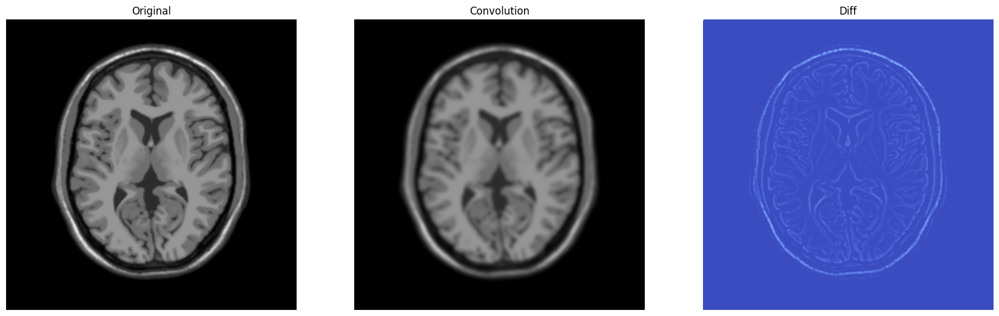

In [58]:
%%time
compare_conv(I_noisefree, convolution(I_noisefree))

CPU times: total: 9.45 s
Wall time: 9.56 s


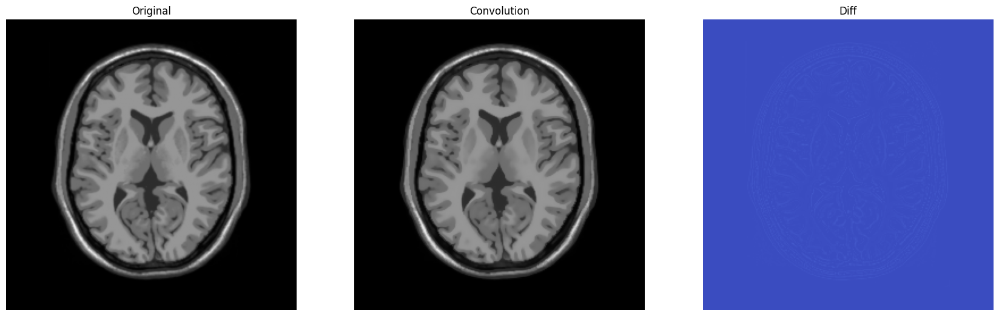

In [59]:
%%time
compare_conv(I_noisefree, bilateral_convolution(I_noisefree))

CPU times: total: 1min 53s
Wall time: 1min 54s


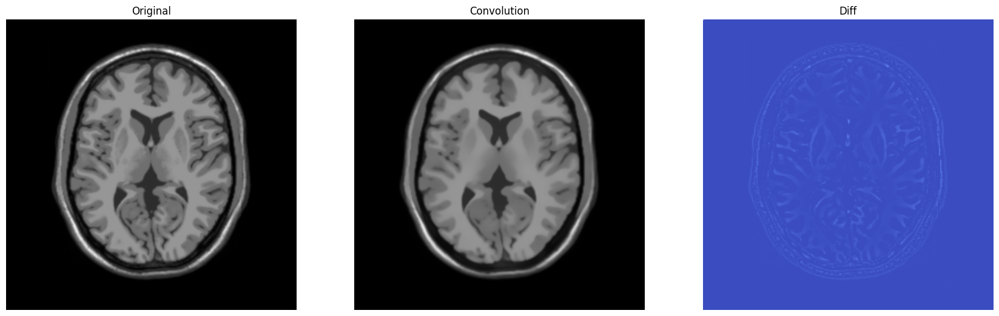

In [60]:
%%time
compare_conv(I_noisefree, nlm(I_noisefree))

CPU times: total: 641 ms
Wall time: 640 ms


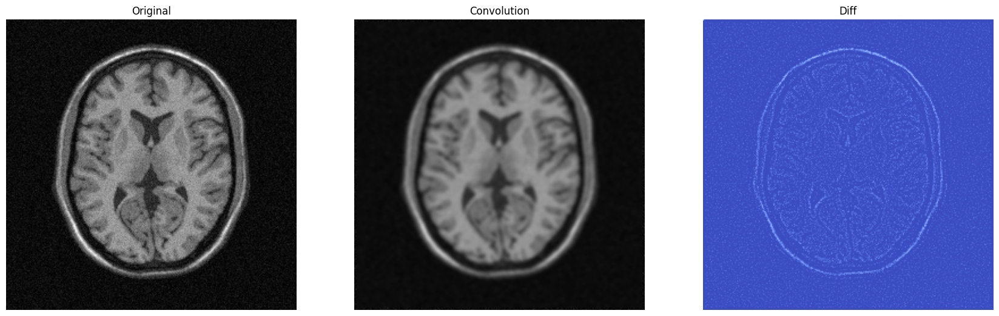

In [61]:
%%time
compare_conv(I_noisy1, convolution(I_noisy1))

CPU times: total: 9.44 s
Wall time: 9.44 s


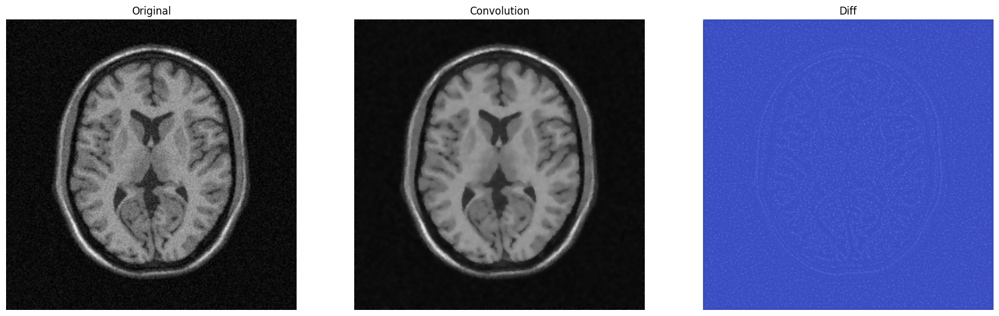

In [73]:
%%time
compare_conv(I_noisy1, bilateral_convolution(I_noisy1, sigma_R=25.0))

CPU times: total: 1min 48s
Wall time: 1min 49s


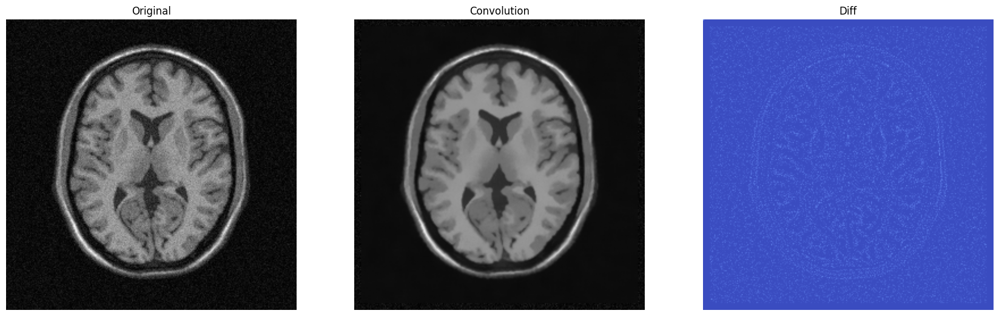

In [63]:
%%time
compare_conv(I_noisy1, nlm(I_noisy1))

CPU times: total: 641 ms
Wall time: 650 ms


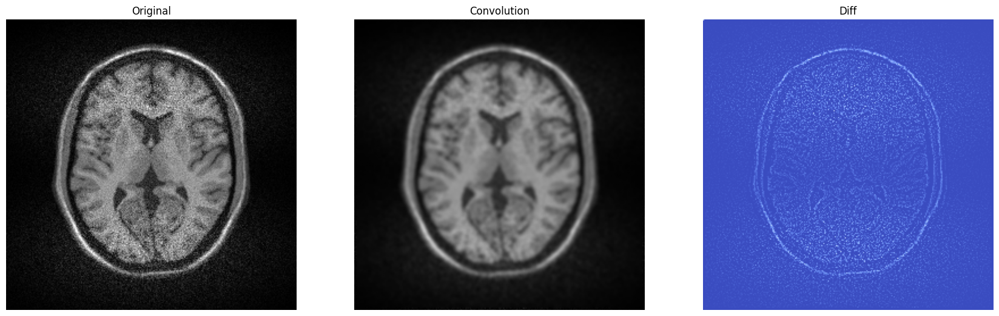

In [64]:
%%time
compare_conv(I_noisy2, convolution(I_noisy2))

CPU times: total: 9.45 s
Wall time: 9.49 s


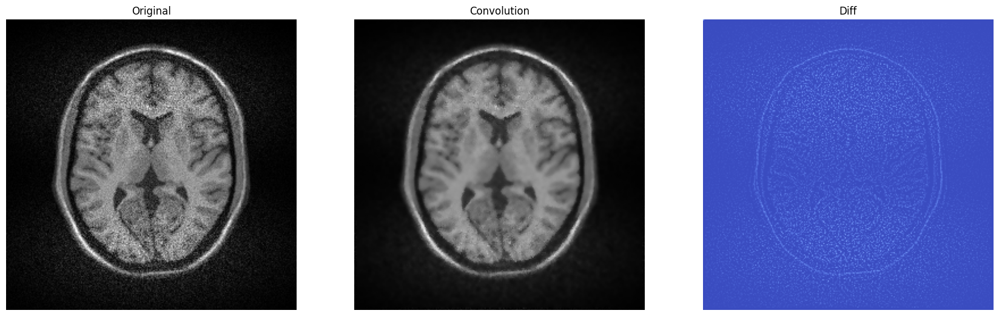

In [75]:
%%time
compare_conv(I_noisy2, bilateral_convolution(I_noisy2, sigma_R = 50.0))

CPU times: total: 1min 43s
Wall time: 1min 44s


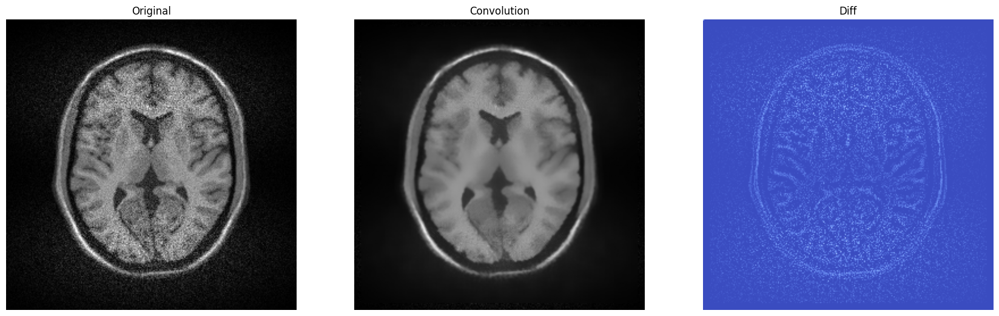

In [ ]:
%%time
compare_conv(I_noisy2, nlm(I_noisy2, alpha=0.5, sigma=20.0))

CPU times: total: 3.31 s
Wall time: 3.32 s


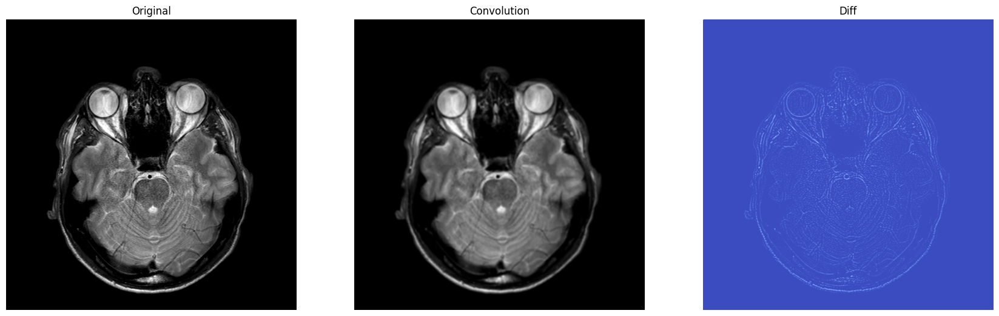

In [67]:
%%time
compare_conv(I_noisy3, convolution(I_noisy3))

CPU times: total: 51.7 s
Wall time: 52.2 s


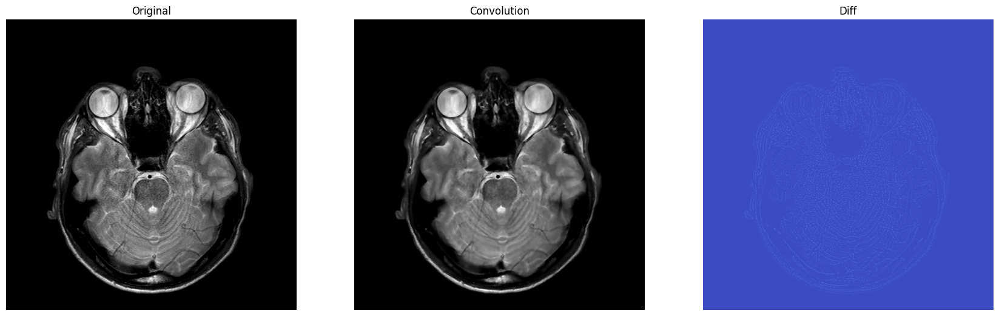

In [80]:
%%time
compare_conv(I_noisy3, bilateral_convolution(I_noisy3, sigma_R=25.0))

CPU times: total: 10min 45s
Wall time: 10min 52s


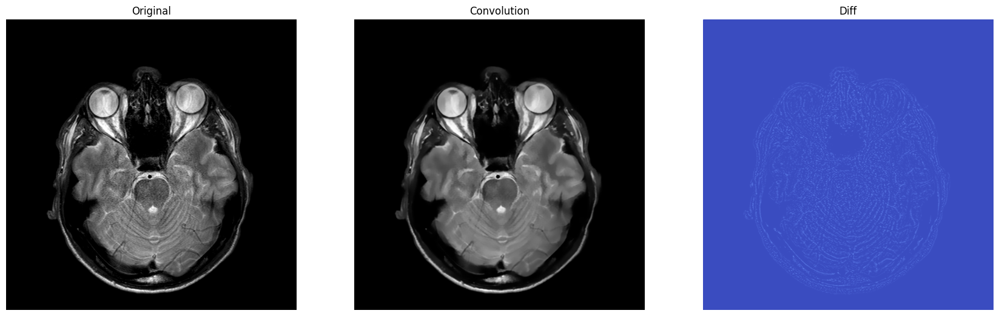

In [69]:
%%time
compare_conv(I_noisy3, nlm(I_noisy3))

CPU times: total: 3.06 s
Wall time: 3.09 s


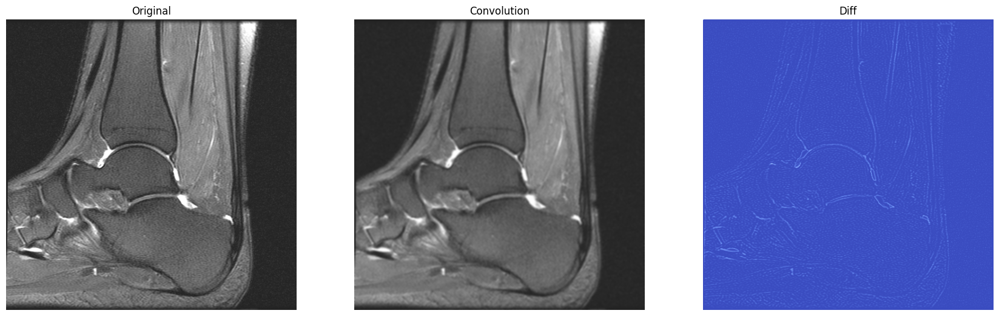

In [70]:
%%time
compare_conv(I_noisy4, convolution(I_noisy4))

CPU times: total: 42.2 s
Wall time: 42.9 s


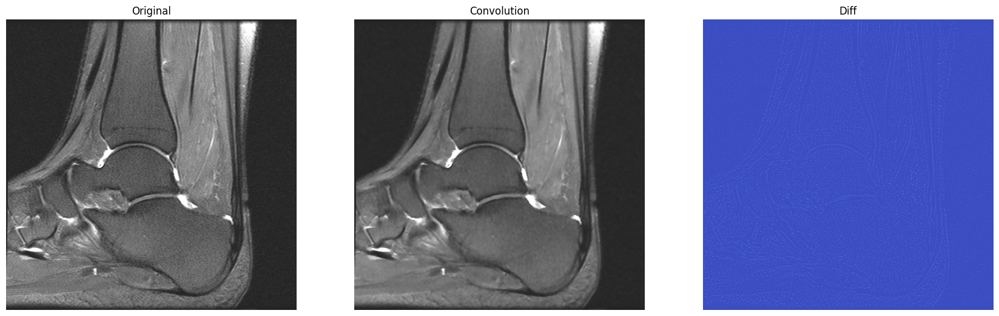

In [71]:
%%time
compare_conv(I_noisy4, bilateral_convolution(I_noisy4, sigma_R = 25.0))

CPU times: total: 8min 49s
Wall time: 8min 53s


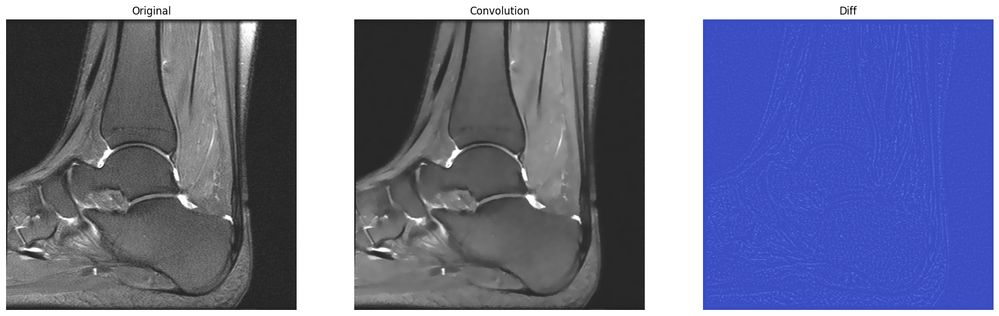

In [72]:
%%time
compare_conv(I_noisy4, nlm(I_noisy4))

## Porównanie jakości wyników filtracji

Filtr Gaussa skutecznie redukuje szum, jednak rozmywa krawędzie i detale obrazu, co jest szczególnie widoczne na obrazach z większym poziomem szumu. Filtr bilateralny lepiej zachowuje krawędzie obiektów dzięki uwzględnianiu różnic w jasności pikseli, co pozwala na lepszą ochronę struktury obrazu podczas redukcji szumu. Filtr Non-Local Means oferuje najlepszą jakość odszumiania spośród trzech badanych metod, szczególnie w przypadku złożonych tekstur i detali, dzięki porównywaniu lokalnych kontekstów zamiast pojedynczych pikseli.

## Porównianie czasów działania

Filtr Gaussa jest zdecydowanie najszybszą metodą, filtr bilateralny wymaga około kilkukrotnie więcej czasu, natomiast filtr NLM jest znacząco wolniejszy od pozostałych (nawet kilkudziesięciokrotnie)